# Assignment 8: NLP-II: Text Features and Generation

**UCS420 : Cognitive Computing**  
**Name:** Harshpreet Singh  
**Roll Number:** 1024170162  
**Branch:** Computer Science and Engineering

## Setup

In [1]:
%pip install nltk scikit-learn textblob wordcloud matplotlib tensorflow

  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------------------------ --------------- 1.0/1.7 MB 2.4 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 3.2 MB/s  0:00:00
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.4 MB 7.6 MB/s eta 0:00:01
   ---------------- ----------------------- 3.4/8.4 MB 8.3 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.4 MB 9.0 MB/s eta 0:00:01
   ------------------------------------ --- 7.6/8.4 MB 9.5 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 9.4 MB/s  0:

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## Q1. Text preprocessing, tokenization and word frequency

In [2]:
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)

text = """Classical music is an important part of my daily life.
I enjoy learning new ragas and practising different musical patterns.
Each raga creates a special mood through its notes and phrases.
Regular practice helps me improve my listening skills and concentration.
Music also connects me with culture and gives me a peaceful break from studies."""

print("Original text:")
print(text)

lower_text = text.lower()
clean_text = re.sub(r'[^a-zA-Z0-9\s]', '', lower_text)
print("\nClean text (lowercase and punctuation removed):")
print(clean_text)

sentences = re.split(r'(?<=[.!?])\s+', text.strip())
print("\nSentences:")
for sentence in sentences:
    print(sentence)

split_words = clean_text.split()
print("\nWords using split():")
print(split_words)

nltk_words = word_tokenize(clean_text, preserve_line=True)
print("\nWords using NLTK word_tokenize():")
print(nltk_words)

print("\nComparison:")
print("split() separates text wherever there is whitespace.")
print("word_tokenize() uses language tokenization rules; it can separate punctuation and handle contractions differently. Since punctuation was removed here, both lists are expected to be very similar.")

stop_words = set(stopwords.words("english"))
useful_words = []
for word in nltk_words:
    if word not in stop_words:
        useful_words.append(word)

print("\nWords after removing stopwords:")
print(useful_words)

frequency = FreqDist(useful_words)
print("\nWord frequency:")
for word, count in frequency.items():
    print(word, ":", count)


Original text:
Classical music is an important part of my daily life.
I enjoy learning new ragas and practising different musical patterns.
Each raga creates a special mood through its notes and phrases.
Regular practice helps me improve my listening skills and concentration.
Music also connects me with culture and gives me a peaceful break from studies.

Clean text (lowercase and punctuation removed):
classical music is an important part of my daily life
i enjoy learning new ragas and practising different musical patterns
each raga creates a special mood through its notes and phrases
regular practice helps me improve my listening skills and concentration
music also connects me with culture and gives me a peaceful break from studies

Sentences:
Classical music is an important part of my daily life.
I enjoy learning new ragas and practising different musical patterns.
Each raga creates a special mood through its notes and phrases.
Regular practice helps me improve my listening skills an

## Q2. Stemming and lemmatization

In [3]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
words_without_stopwords = []
for word in words:
    if word not in stop_words:
        words_without_stopwords.append(word)

print("Words after removing stopwords:")
print(words_without_stopwords)

stemmer = PorterStemmer()
stemmed_words = []
for word in words_without_stopwords:
    stemmed_words.append(stemmer.stem(word))
print("\nPorter stemmed words:")
print(stemmed_words)

nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in words_without_stopwords]
print("\nWordNet lemmatized words:")
print(lemmatized_words)

print("\nWord | Stem | Lemma")
for original, stem, lemma in zip(words_without_stopwords, stemmed_words, lemmatized_words):
    if stem != lemma:
        print(original, "|", stem, "|", lemma)

print("\nComparison:")
print("Stemming cuts word endings and may create a word that is not a dictionary word.")
print("Lemmatization aims to return a meaningful dictionary form. WordNet provides the dictionary-based forms.")


Words after removing stopwords:
['classical', 'music', 'important', 'part', 'daily', 'life', 'enjoy', 'learning', 'new', 'ragas', 'practising', 'different', 'musical', 'patterns', 'raga', 'creates', 'special', 'mood', 'notes', 'phrases', 'regular', 'practice', 'helps', 'improve', 'listening', 'skills', 'concentration', 'music', 'also', 'connects', 'culture', 'gives', 'peaceful', 'break', 'studies']

Porter stemmed words:
['classic', 'music', 'import', 'part', 'daili', 'life', 'enjoy', 'learn', 'new', 'raga', 'practis', 'differ', 'music', 'pattern', 'raga', 'creat', 'special', 'mood', 'note', 'phrase', 'regular', 'practic', 'help', 'improv', 'listen', 'skill', 'concentr', 'music', 'also', 'connect', 'cultur', 'give', 'peac', 'break', 'studi']

WordNet lemmatized words:
['classical', 'music', 'important', 'part', 'daily', 'life', 'enjoy', 'learning', 'new', 'ragas', 'practising', 'different', 'musical', 'pattern', 'raga', 'creates', 'special', 'mood', 'note', 'phrase', 'regular', 'practi

**Comparison:** Stemming removes word endings and may create a form that is not a dictionary word. Lemmatization tries to return a meaningful dictionary word. Stemming is useful when speed matters; lemmatization is useful when readable word forms matter.

## Q3. Bag of Words and TF-IDF

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps computers learn from data.",
    "Machine learning is used in artificial intelligence.",
    "Data science uses data to find useful information."
]

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words terms:")
print(count_vectorizer.get_feature_names_out())
print("Bag of Words matrix:")
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

words = tfidf_vectorizer.get_feature_names_out()
scores = tfidf_matrix.toarray()

print("\nTF-IDF matrix:")
print(scores)

print("\nTop 3 keywords from each text:")
for i in range(len(texts)):
    word_scores = []
    for j in range(len(words)):
        word_scores.append((words[j], scores[i][j]))

    word_scores.sort(key=lambda item: item[1], reverse=True)

    print("\nText", i + 1)
    for j in range(3):
        print(word_scores[j][0], ":", round(word_scores[j][1], 3))

Bag of Words terms:
['artificial' 'computers' 'data' 'find' 'from' 'helps' 'in' 'information'
 'intelligence' 'is' 'learn' 'learning' 'machine' 'science' 'to' 'used'
 'useful' 'uses']
Bag of Words matrix:
[[1 1 1 0 1 1 0 0 1 0 1 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 1 0 1 1 0 1 1 0 0 1 0 0]
 [0 0 2 1 0 0 0 1 0 0 0 0 0 1 1 0 1 1]]

TF-IDF matrix:
[[0.31757018 0.41756662 0.31757018 0.         0.41756662 0.41756662
  0.         0.         0.31757018 0.         0.41756662 0.
  0.         0.         0.         0.         0.         0.        ]
 [0.30650422 0.         0.         0.         0.         0.
  0.40301621 0.         0.30650422 0.40301621 0.         0.40301621
  0.40301621 0.         0.         0.40301621 0.         0.        ]
 [0.         0.         0.52753275 0.34682109 0.         0.
  0.         0.34682109 0.         0.         0.         0.
  0.         0.34682109 0.34682109 0.         0.34682109 0.34682109]]

Top 3 keywords from each text:

Text 1
computers : 0.418
from : 0.418
helps 

**Interpretation:** Bag of Words counts each word. TF-IDF gives more importance to words that are useful in one text and less importance to words that appear in many texts. The three printed words are the highest-scoring keywords for each text.

## Q4. Similarity between two technologies

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ai_text = """Artificial intelligence allows computers to perform tasks.
It can learn from data and identify patterns.
AI is used in healthcare, education and transport.
It helps people make better decisions.
AI systems can improve with experience."""

blockchain_text = """Blockchain stores information in digital blocks.
These blocks are connected in a secure chain.
It is used in digital currencies and record keeping.
Blockchain makes stored information difficult to change.
It can provide transparency and security."""

ai_words = re.findall(r'\b[a-zA-Z]+\b', ai_text.lower())
blockchain_words = re.findall(r'\b[a-zA-Z]+\b', blockchain_text.lower())

print("AI words:")
print(ai_words)
print("\nBlockchain words:")
print(blockchain_words)

ai_set = set(ai_words)
blockchain_set = set(blockchain_words)

common_words = ai_set.intersection(blockchain_set)
all_words = ai_set.union(blockchain_set)

jaccard = len(common_words) / len(all_words)
print("\nCommon words:", common_words)
print("Jaccard similarity:", round(jaccard, 3))

documents = [ai_text, blockchain_text]
vectorizer = TfidfVectorizer()
tfidf_values = vectorizer.fit_transform(documents)

cosine = cosine_similarity(tfidf_values[0:1], tfidf_values[1:2])
print("Cosine similarity:", round(cosine[0][0], 3))

AI words:
['artificial', 'intelligence', 'allows', 'computers', 'to', 'perform', 'tasks', 'it', 'can', 'learn', 'from', 'data', 'and', 'identify', 'patterns', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transport', 'it', 'helps', 'people', 'make', 'better', 'decisions', 'ai', 'systems', 'can', 'improve', 'with', 'experience']

Blockchain words:
['blockchain', 'stores', 'information', 'in', 'digital', 'blocks', 'these', 'blocks', 'are', 'connected', 'in', 'a', 'secure', 'chain', 'it', 'is', 'used', 'in', 'digital', 'currencies', 'and', 'record', 'keeping', 'blockchain', 'makes', 'stored', 'information', 'difficult', 'to', 'change', 'it', 'can', 'provide', 'transparency', 'and', 'security']

Common words: {'to', 'it', 'in', 'and', 'is', 'used', 'can'}
Jaccard similarity: 0.135
Cosine similarity: 0.209


**Analysis:** Jaccard similarity compares common words with all unique words. Cosine similarity compares the TF-IDF vectors. Cosine similarity can give more useful information here because it considers word importance, while Jaccard treats all unique words equally.

## Q5. Sentiment analysis and word cloud


Review: This product is excellent and very useful.
Polarity: 0.7
Subjectivity: 0.5
Sentiment: Positive

Review: I am happy with the quality and performance.
Polarity: 0.8
Subjectivity: 1.0
Sentiment: Positive

Review: The product is terrible and disappointing.
Polarity: -0.8
Subjectivity: 0.85
Sentiment: Negative

Review: I do not like this service.
Polarity: 0.0
Subjectivity: 0.0
Sentiment: Neutral

Review: The product is okay.
Polarity: 0.5
Subjectivity: 0.5
Sentiment: Positive

Review: It is an average experience.
Polarity: -0.15
Subjectivity: 0.4
Sentiment: Negative


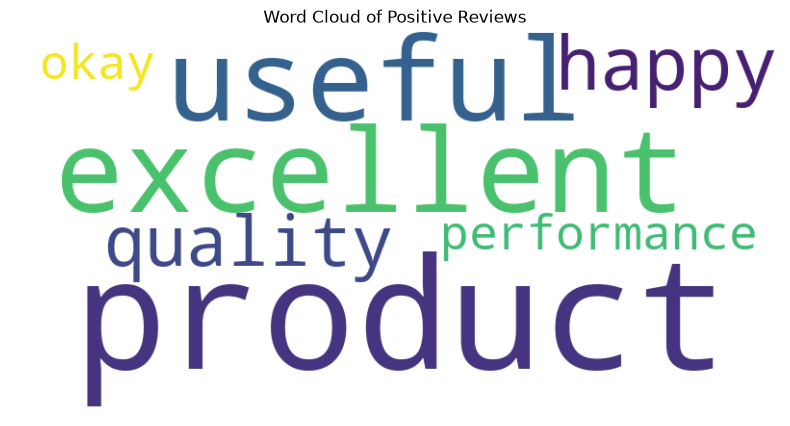

In [6]:
from textblob import TextBlob
import matplotlib.pyplot as plt
from wordcloud import WordCloud

reviews = [
    "This product is excellent and very useful.",
    "I am happy with the quality and performance.",
    "The product is terrible and disappointing.",
    "I do not like this service.",
    "The product is okay.",
    "It is an average experience."
]

positive_reviews = []

for review in reviews:
    analysis = TextBlob(review)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 2))
    print("Subjectivity:", round(subjectivity, 2))
    print("Sentiment:", sentiment)

positive_text = " ".join(positive_reviews)

if positive_text:
    wordcloud = WordCloud(width=800, height=400, background_color="white")
    wordcloud.generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()

**Note:** Polarity tells whether a review is positive or negative. Subjectivity tells how much the review expresses an opinion rather than a fact. The word cloud shows common words from positive reviews.

## Q6. Text generation using a simple Dense model

In [ ]:

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense

training_text = """
Technology has changed the way people live and work.
Computers help us solve problems and complete tasks quickly.
Artificial intelligence allows machines to learn from data.
Machine learning is used in healthcare, education and business.
Technology connects people across different parts of the world.
Students use computers to learn new concepts and develop skills.
Artificial intelligence can analyse information and make predictions.
Technology continues to create new opportunities for society.
Learning about technology helps us prepare for the future.
Innovation makes everyday activities easier and more efficient.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1

input_sequences = []

for line in training_text.split('.'):
    sequence = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(sequence)):
        input_sequences.append(sequence[i-1:i+1])

X = np.array([seq[0] for seq in input_sequences])
y = np.array([seq[1] for seq in input_sequences])

model = Sequential()
model.add(Embedding(total_words, 16))
model.add(Flatten())
model.add(Dense(32, activation='relu'))
model.add(Dense(total_words, activation='softmax'))

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=100, verbose=0)

print("Model training completed!")

# Step 5: Generate new text
def generate_text(seed_word, next_words=8):
    word = seed_word.lower()

    if word not in tokenizer.word_index:
        print("Seed word not found. Using 'technology' instead.")
        word = "technology"

    for _ in range(next_words):
        encoded = tokenizer.texts_to_sequences([word.split()])[-1]
        prediction = model.predict(
            np.array([encoded[-1]]), verbose=0
        )
        predicted_index = np.argmax(prediction)

        output_word = tokenizer.index_word.get(predicted_index, "")

        if output_word == "":
            break

        word += " " + output_word

    return word

# Generate 3 lines
print("\nGenerated Text:")
for seed in ["technology", "students", "learning"]:
    print(generate_text(seed, 8))


Model training completed!

Generated Text:
technology helps us prepare for the future and work
students use computers to learn new concepts and work
learning about technology helps us prepare for the future


**Explanation:**
1. `Tokenizer()` converts words into numbers.
2. Input sequences are made from the training paragraph.
3. A small Dense neural network learns to predict the next word.
4. The function starts with a seed word and generates more words.

The generated text may not be grammatically correct because the training paragraph is small.